# Oral Cancer Outcomes Across South Asia, GLOBOCAN 2022

A secondary analysis of public GLOBOCAN 2022 estimates for lip and oral cavity cancer in Pakistan, India, Bangladesh and Sri Lanka.

**Research question:** How does the mortality-to-incidence ratio for lip and oral cavity cancer differ across Pakistan, India, Bangladesh and Sri Lanka in 2022?

**Supporting questions**
1. Which country holds the largest share of regional cases and deaths?
2. Do countries with a higher mortality ratio show fewer five-year prevalent patients per new case?

## 1. Data

Source: GLOBOCAN 2022, International Agency for Research on Cancer (IARC), https://gco.iarc.who.int. Values were transcribed by hand from the IARC country fact sheets (links are in the data files). Site: lip, oral cavity. All ages.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("data/globocan2022_south_asia_oral_cancer.csv").rename(columns={
    "New_cases_both_sexes": "New_cases",
    "Deaths_both_sexes": "Deaths",
    "Five_year_prevalence_both_sexes": "Five_year_prevalence",
})
df[["Country", "Cancer_site", "New_cases", "Deaths", "Five_year_prevalence"]]

,Country,Cancer_site,New_cases,Deaths,Five_year_prevalence
0,Pakistan,"Lip, oral cavity",15915,10181,36318
1,India,"Lip, oral cavity",143759,79979,370106
2,Bangladesh,"Lip, oral cavity",16083,9447,40190
3,Sri Lanka,"Lip, oral cavity",2556,1198,7490


## 2. Methods

- **Mortality-to-incidence ratio** = deaths / new cases. The main outcome and a common proxy for survival and access to care.
- **Prevalence per new case** = five-year prevalence / new cases. A second measure of how many patients live after diagnosis.
- **Share of the four-country total** for cases and deaths.

In [2]:
df["Mortality_to_incidence_ratio"] = (df["Deaths"] / df["New_cases"]).round(3)
df["Prevalence_per_new_case"] = (df["Five_year_prevalence"] / df["New_cases"]).round(2)
df["Share_of_cases_pct"] = (100 * df["New_cases"] / df["New_cases"].sum()).round(1)
df["Share_of_deaths_pct"] = (100 * df["Deaths"] / df["Deaths"].sum()).round(1)
df = df.sort_values("Mortality_to_incidence_ratio", ascending=False).reset_index(drop=True)

results = df[["Country", "New_cases", "Deaths", "Mortality_to_incidence_ratio",
              "Prevalence_per_new_case", "Share_of_cases_pct", "Share_of_deaths_pct"]]
results

,Country,New_cases,Deaths,Mortality_to_incidence_ratio,Prevalence_per_new_case,Share_of_cases_pct,Share_of_deaths_pct
0,Pakistan,15915,10181,0.640,2.28,8.9,10.1
1,Bangladesh,16083,9447,0.587,2.50,9.0,9.4
2,India,143759,79979,0.556,2.57,80.6,79.3
3,Sri Lanka,2556,1198,0.469,2.93,1.4,1.2


## 3. Results

### 3.1 Mortality-to-incidence ratio

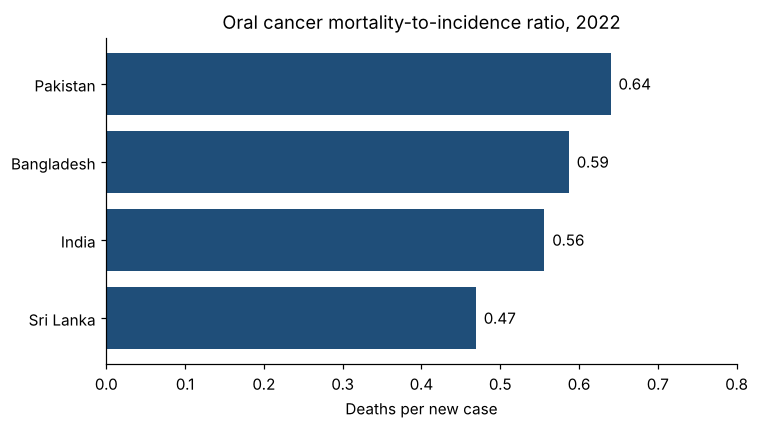

In [3]:
d = df.sort_values("Mortality_to_incidence_ratio")
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.barh(d["Country"], d["Mortality_to_incidence_ratio"], color="#1f4e79")
for b, v in zip(bars, d["Mortality_to_incidence_ratio"]):
    ax.text(v + 0.01, b.get_y() + b.get_height() / 2, f"{v:.2f}", va="center")
ax.set_xlim(0, 0.8)
ax.set_xlabel("Deaths per new case")
ax.set_title("Oral cancer mortality-to-incidence ratio, 2022")
plt.tight_layout()
plt.show()

Pakistan has the highest ratio (0.64) and Sri Lanka the lowest (0.47). Pakistan's ratio is 36% higher.

### 3.2 Five-year prevalence per new case

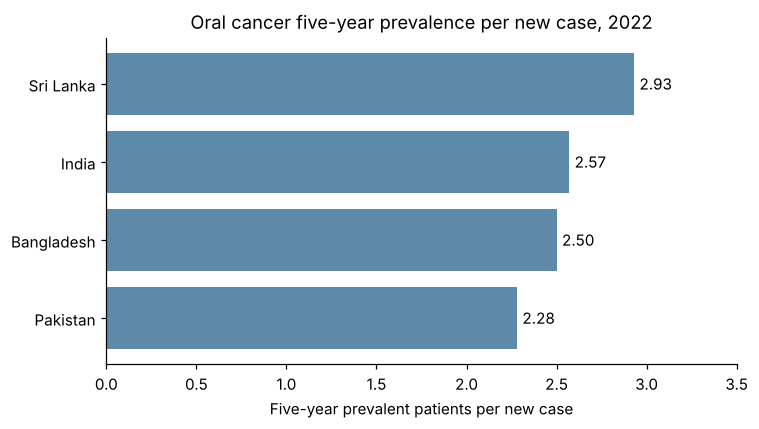

In [4]:
d = df.sort_values("Prevalence_per_new_case")
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.barh(d["Country"], d["Prevalence_per_new_case"], color="#5d8aa8")
for b, v in zip(bars, d["Prevalence_per_new_case"]):
    ax.text(v + 0.03, b.get_y() + b.get_height() / 2, f"{v:.2f}", va="center")
ax.set_xlim(0, 3.5)
ax.set_xlabel("Five-year prevalent patients per new case")
ax.set_title("Oral cancer five-year prevalence per new case, 2022")
plt.tight_layout()
plt.show()

The order runs opposite to the mortality ratio. Sri Lanka has the most prevalent patients per new case (2.93) and Pakistan the fewest (2.28). Two measures point the same way.

### 3.3 Share of regional cases and deaths

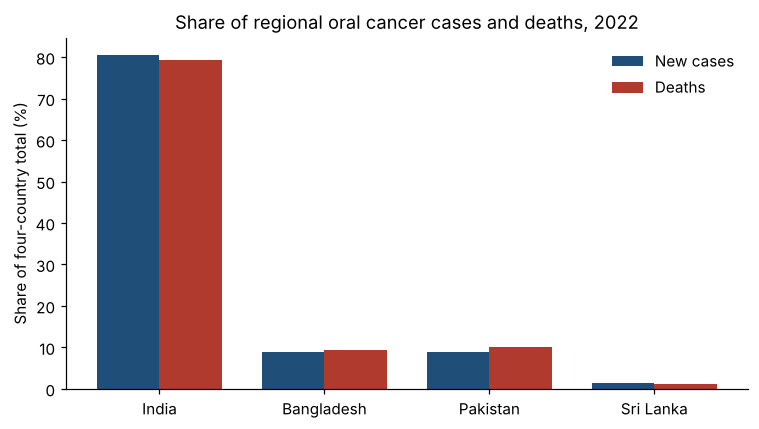

In [5]:
d = df.sort_values("Share_of_cases_pct", ascending=False)
x = list(range(len(d)))
w = 0.38
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar([i - w / 2 for i in x], d["Share_of_cases_pct"], w, label="New cases", color="#1f4e79")
ax.bar([i + w / 2 for i in x], d["Share_of_deaths_pct"], w, label="Deaths", color="#b03a2e")
ax.set_xticks(x)
ax.set_xticklabels(d["Country"])
ax.set_ylabel("Share of four-country total (%)")
ax.set_title("Share of regional oral cancer cases and deaths, 2022")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

India holds 80.6% of cases and 79.3% of deaths. Pakistan and Bangladesh each carry a larger share of deaths than of cases. India and Sri Lanka carry a smaller one.

### 3.4 Illustrative scenario: deaths above the best regional ratio

Apply the lowest regional ratio (Sri Lanka) to the new cases of the other three countries and compare with observed deaths. The scenario sizes the gap. It does not claim the gap is avoidable.

In [6]:
best = df["Mortality_to_incidence_ratio"].min()
best_country = df.loc[df["Mortality_to_incidence_ratio"].idxmin(), "Country"]
sc = df[df["Country"] != best_country][["Country", "New_cases", "Deaths"]].copy()
sc["Deaths_at_best_ratio"] = (sc["New_cases"] * best).round(0).astype(int)
sc["Deaths_above_best_ratio"] = sc["Deaths"] - sc["Deaths_at_best_ratio"]
sc = sc.sort_values("Deaths_above_best_ratio", ascending=False).reset_index(drop=True)
print(f"Benchmark: {best_country}, ratio {best:.3f}")
print(f"Total deaths above benchmark: {sc['Deaths_above_best_ratio'].sum():,}")
sc

Benchmark: Sri Lanka, ratio 0.469
Total deaths above benchmark: 17,177


,Country,New_cases,Deaths,Deaths_at_best_ratio,Deaths_above_best_ratio
0,India,143759,79979,67423,12556
1,Pakistan,15915,10181,7464,2717
2,Bangladesh,16083,9447,7543,1904


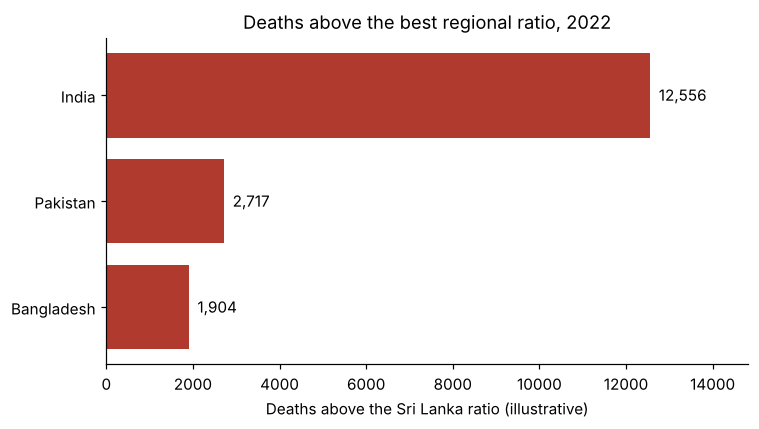

In [7]:
d = sc.sort_values("Deaths_above_best_ratio")
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.barh(d["Country"], d["Deaths_above_best_ratio"], color="#b03a2e")
for b, v in zip(bars, d["Deaths_above_best_ratio"]):
    ax.text(v + 200, b.get_y() + b.get_height() / 2, f"{v:,}", va="center")
ax.set_xlim(0, d["Deaths_above_best_ratio"].max() * 1.18)
ax.set_xlabel(f"Deaths above the {best_country} ratio (illustrative)")
ax.set_title("Deaths above the best regional ratio, 2022")
plt.tight_layout()
plt.show()

## 4. Interpretation

A high ratio points to late diagnosis, limited access to surgery and radiotherapy, weaker follow-up, or incomplete cancer registration. This analysis does not test which of these applies. Two measures agree on the country ranking, which strengthens the pattern. Four countries are too few for statistical testing.

The finding supports a specific next question: what distinguishes Sri Lanka's pathway to diagnosis and treatment from Pakistan's and Bangladesh's? Early detection programmes and treatment access are the first places to look.

## 5. Limitations

1. Country-level data. The results say nothing about individual patients.
2. The ratio is a proxy for survival. Deaths and new cases in one year do not follow the same patients.
3. GLOBOCAN values are modelled estimates. Countries with limited registry coverage carry more uncertainty.
4. Values were transcribed by hand from IARC fact sheets. Check them against the source before citing.
5. No age standardisation. Age structure differs by country.
6. One year and four countries. No trend analysis and no causal claim.
7. The scenario assumes Sri Lanka's ratio is a fair benchmark. Case mix and registry quality differ across countries.

## 6. Next steps

- Add age-standardised rates from GLOBOCAN
- Extend to Nepal, Bhutan, Maldives and Afghanistan
- Add smokeless tobacco prevalence by country to test a risk factor link
- Pair with a patient-level dataset for a clinical study

## Data citation

Ferlay J, Ervik M, Lam F, et al. Global Cancer Observatory: Cancer Today. Lyon, France: International Agency for Research on Cancer, 2024. https://gco.iarc.who.int